# CUDA-Accelerated Cotangent Laplace-Beltrami Solver for Surface Reaction-Diffusion PDEs
$$\frac{\partial u}{\partial t} = D_u \Delta_{\mathcal{M}} u - u v^2 + F(1 - u), \qquad \frac{\partial v}{\partial t} = D_v \Delta_{\mathcal{M}} v + u v^2 - (F + k)v$$

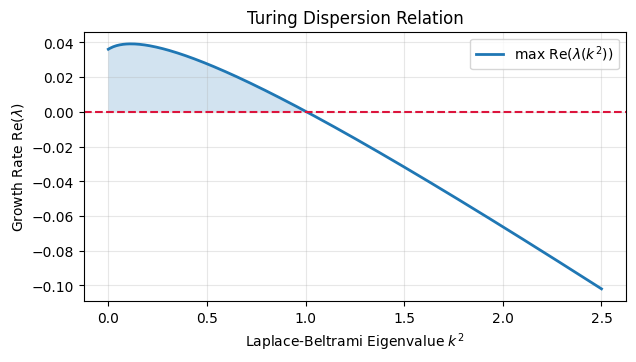

In [ ]:
# STEP 1: SYMBOLIC LINEAR STABILITY ANALYSIS (TURING INSTABILITY)
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

u, v, F, k, Du, Dv, k_sq = sp.symbols('u v F k Du Dv k_sq', real=True, positive=True)
R_u = -u * v**2 + F * (1 - u)
R_v =  u * v**2 - (F + k) * v
J_R = sp.Matrix([[sp.diff(R_u, u), sp.diff(R_u, v)], [sp.diff(R_v, u), sp.diff(R_v, v)]])
J_total = J_R - sp.Matrix([[Du * k_sq, 0], [0, Dv * k_sq]])

params = {F: 0.0545, k: 0.062, Du: 0.16, Dv: 0.08, u: 0.52, v: 0.24}
J_num_func = sp.lambdify(k_sq, J_total.subs(params), 'numpy')
k_sq_vals = np.linspace(0, 2.5, 300)
max_real = [np.max(np.real(np.linalg.eigvals(J_num_func(val)))) for val in k_sq_vals]

plt.figure(figsize=(7, 3.5))
plt.plot(k_sq_vals, max_real, lw=2, label=r'$\max \ \mathrm{Re}(\lambda(k^2))$')
plt.axhline(0, color='crimson', ls='--')
plt.fill_between(k_sq_vals, 0, max_real, where=(np.array(max_real) > 0), alpha=0.2)
plt.xlabel(r'Laplace-Beltrami Eigenvalue $k^2$'); plt.ylabel(r'Growth Rate $\mathrm{Re}(\lambda)$')
plt.title('Turing Dispersion Relation'); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 2. Discrete Differential Geometry & CSR Serialization

In [ ]:
# STEP 2: LOAD 3D MESH & ASSEMBLE COTANGENT LAPLACE-BELTRAMI OPERATOR IN CSR
import urllib.request, os, struct
from scipy import sparse

obj_url = 'https://raw.githubusercontent.com/alecjacobson/common-3d-test-models/master/data/stanford-bunny.obj'
if not os.path.exists('stanford_bunny.obj'): urllib.request.urlretrieve(obj_url, 'stanford_bunny.obj')

vertices, faces = [], []
with open('stanford_bunny.obj') as f:
    for line in f:
        p = line.strip().split()
        if not p: continue
        if p[0] == 'v': vertices.append([float(p[1]), float(p[2]), float(p[3])])
        elif p[0] == 'f': faces.append([int(x.split('/')[0]) - 1 for x in p[1:4]])

V, F_mesh = np.array(vertices, dtype=np.float64), np.array(faces, dtype=np.int32)
num_v, num_f = V.shape[0], F_mesh.shape[0]
v0, v1, v2 = V[F_mesh[:, 0]], V[F_mesh[:, 1]], V[F_mesh[:, 2]]
e0, e1, e2 = v2 - v1, v0 - v2, v1 - v0
dbl_area = np.maximum(np.linalg.norm(np.cross(e2, -e1), axis=1), 1e-12)
tri_area = 0.5 * dbl_area

cot0 = np.clip(0.5 * np.sum((-e1) * e2, axis=1) / dbl_area, 0.01, 10.0)
cot1 = np.clip(0.5 * np.sum((-e2) * e0, axis=1) / dbl_area, 0.01, 10.0)
cot2 = np.clip(0.5 * np.sum((-e0) * e1, axis=1) / dbl_area, 0.01, 10.0)

rows = np.concatenate([F_mesh[:, 1], F_mesh[:, 2], F_mesh[:, 2], F_mesh[:, 0], F_mesh[:, 0], F_mesh[:, 1]])
cols = np.concatenate([F_mesh[:, 2], F_mesh[:, 1], F_mesh[:, 0], F_mesh[:, 2], F_mesh[:, 1], F_mesh[:, 0]])
vals = np.concatenate([cot0, cot0, cot1, cot1, cot2, cot2])
W_csr = sparse.coo_matrix((vals, (rows, cols)), shape=(num_v, num_v)).tocsr()
W_csr.sum_duplicates()

vertex_areas = np.zeros(num_v, dtype=np.float64)
for k_idx in range(3): np.add.at(vertex_areas, F_mesh[:, k_idx], tri_area / 3.0)
row_sums = np.array(W_csr.sum(axis=1)).flatten()
raw_stiffness = row_sums / np.maximum(vertex_areas, 1e-12)
inv_area = np.clip(raw_stiffness / (np.median(raw_stiffness) / 4.0), 0.0, 8.0) / np.maximum(row_sums, 1e-12)

np.random.seed(42)
u_init, v_init = np.ones(num_v, dtype=np.float32), np.zeros(num_v, dtype=np.float32)
for idx in np.random.choice(num_v, size=25, replace=False):
    mask = np.linalg.norm(V - V[idx], axis=1) < 0.012
    u_init[mask] = 0.50 + 0.05 * np.random.rand(np.sum(mask))
    v_init[mask] = 0.25 + 0.05 * np.random.rand(np.sum(mask))

with open('mesh_csr.bin', 'wb') as f:
    f.write(struct.pack('ii', num_v, W_csr.nnz))
    f.write(W_csr.indptr.astype(np.int32).tobytes())
    f.write(W_csr.indices.astype(np.int32).tobytes())
    f.write(W_csr.data.astype(np.float32).tobytes())
    f.write(inv_area.astype(np.float32).tobytes())
    f.write(u_init.tobytes()); f.write(v_init.tobytes())
print(f'Exported CSR mesh ({num_v:,} vertices, {W_csr.nnz:,} directed edges)')

Exported CSR mesh (35,947 vertices, 208,576 directed edges)


## 3. CUDA C++ CSR SpMV & Time-Integration Kernel

In [ ]:
!pip install nvcc4jupyter
%load_ext nvcc4jupyter

The nvcc4jupyter extension is already loaded. To reload it, use:
  %reload_ext nvcc4jupyter


In [ ]:
%%writefile surface_rd_solver.cu
#include <cuda_runtime.h>
#include <stdio.h>
#include <stdlib.h>
#include <math.h>

#define CUDA_CHECK(call) \
    do { \
        cudaError_t err = call; \
        if (err != cudaSuccess) { \
            fprintf(stderr, "CUDA Error %s:%d: %s\n", __FILE__, __LINE__, cudaGetErrorString(err)); \
            exit(EXIT_FAILURE); \
        } \
    } while (0)

__global__ void gray_scott_surface_step_kernel(
    const int num_v,
    const int* __restrict__ row_ptr,
    const int* __restrict__ col_idx,
    const float* __restrict__ weights,
    const float* __restrict__ inv_area,
    const float* __restrict__ u_in,
    const float* __restrict__ v_in,
    float* __restrict__ u_out,
    float* __restrict__ v_out,
    float* __restrict__ dv_dt_sq,
    const float Du, const float Dv, const float F, const float k, const float dt)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= num_v) return;

    float ui = __ldg(&u_in[i]);
    float vi = __ldg(&v_in[i]);
    float flux_u = 0.0f, flux_v = 0.0f;

    int start = __ldg(&row_ptr[i]);
    int end   = __ldg(&row_ptr[i + 1]);

    for (int idx = start; idx < end; ++idx) {
        int j = __ldg(&col_idx[idx]);
        float w = __ldg(&weights[idx]);
        flux_u += w * (__ldg(&u_in[j]) - ui);
        flux_v += w * (__ldg(&v_in[j]) - vi);
    }

    float inv_Ai = __ldg(&inv_area[i]);
    float uvv = ui * vi * vi;

    float du_dt = Du * inv_Ai * flux_u - uvv + F * (1.0f - ui);
    float dv_dt = Dv * inv_Ai * flux_v + uvv - (F + k) * vi;

    u_out[i] = fminf(fmaxf(ui + dt * du_dt, 0.0f), 1.0f);
    v_out[i] = fminf(fmaxf(vi + dt * dv_dt, 0.0f), 1.0f);
    dv_dt_sq[i] = dv_dt * dv_dt;
}

int main(int argc, char** argv) {
    float F = (argc > 1) ? atof(argv[1]) : 0.0545f;
    float k = (argc > 2) ? atof(argv[2]) : 0.0620f;
    const char* out_file = (argc > 3) ? argv[3] : "solution_uv.bin";

    FILE* f = fopen("mesh_csr.bin", "rb");
    if (!f) return 1;

    int num_v, nnz;
    fread(&num_v, sizeof(int), 1, f);
    fread(&nnz, sizeof(int), 1, f);

    int *h_row_ptr = (int*)malloc((num_v + 1) * sizeof(int));
    int *h_col_idx = (int*)malloc(nnz * sizeof(int));
    float *h_weights = (float*)malloc(nnz * sizeof(float));
    float *h_inv_area = (float*)malloc(num_v * sizeof(float));
    float *h_u = (float*)malloc(num_v * sizeof(float));
    float *h_v = (float*)malloc(num_v * sizeof(float));
    float *h_dv_sq = (float*)malloc(num_v * sizeof(float));

    fread(h_row_ptr, sizeof(int), num_v + 1, f);
    fread(h_col_idx, sizeof(int), nnz, f);
    fread(h_weights, sizeof(float), nnz, f);
    fread(h_inv_area, sizeof(float), num_v, f);
    fread(h_u, sizeof(float), num_v, f);
    fread(h_v, sizeof(float), num_v, f);
    fclose(f);

    int *d_row_ptr, *d_col_idx;
    float *d_weights, *d_inv_area, *d_u0, *d_v0, *d_u1, *d_v1, *d_dv_sq;

    CUDA_CHECK(cudaMalloc(&d_row_ptr, (num_v + 1) * sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_col_idx, nnz * sizeof(int)));
    CUDA_CHECK(cudaMalloc(&d_weights, nnz * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_inv_area, num_v * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_u0, num_v * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_v0, num_v * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_u1, num_v * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_v1, num_v * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d_dv_sq, num_v * sizeof(float)));

    CUDA_CHECK(cudaMemcpy(d_row_ptr, h_row_ptr, (num_v + 1) * sizeof(int), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_col_idx, h_col_idx, nnz * sizeof(int), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_weights, h_weights, nnz * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_inv_area, h_inv_area, num_v * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_u0, h_u, num_v * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_v0, h_v, num_v * sizeof(float), cudaMemcpyHostToDevice));

    const int steps = 12000;
    int block = 256, grid = (num_v + block - 1) / block;

    cudaEvent_t start, stop;
    CUDA_CHECK(cudaEventCreate(&start));
    CUDA_CHECK(cudaEventCreate(&stop));
    CUDA_CHECK(cudaEventRecord(start));

    for (int s = 0; s < steps; ++s) {
        if (s % 2 == 0)
            gray_scott_surface_step_kernel<<<grid, block>>>(num_v, d_row_ptr, d_col_idx, d_weights, d_inv_area, d_u0, d_v0, d_u1, d_v1, d_dv_sq, 0.16f, 0.08f, F, k, 0.5f);
        else
            gray_scott_surface_step_kernel<<<grid, block>>>(num_v, d_row_ptr, d_col_idx, d_weights, d_inv_area, d_u1, d_v1, d_u0, d_v0, d_dv_sq, 0.16f, 0.08f, F, k, 0.5f);
    }

    CUDA_CHECK(cudaEventRecord(stop));
    CUDA_CHECK(cudaEventSynchronize(stop));

    float ms = 0.0f;
    CUDA_CHECK(cudaEventElapsedTime(&ms, start, stop));
    double bytes = (double)(num_v + 1) * 4 + (double)nnz * 8 + (double)num_v * 24;
    printf("Regime (F=%.4f, k=%.4f) | Steps: %d | Time: %.2f ms | Bandwidth: %.2f GB/s\n", F, k, steps, ms, (bytes * steps) / (ms * 1e6));

    CUDA_CHECK(cudaMemcpy(h_u, d_u0, num_v * sizeof(float), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(h_v, d_v0, num_v * sizeof(float), cudaMemcpyDeviceToHost));

    FILE* out = fopen(out_file, "wb");
    fwrite(h_u, sizeof(float), num_v, out);
    fwrite(h_v, sizeof(float), num_v, out);
    fclose(out);

    cudaFree(d_row_ptr); cudaFree(d_col_idx); cudaFree(d_weights); cudaFree(d_inv_area);
    cudaFree(d_u0); cudaFree(d_v0); cudaFree(d_u1); cudaFree(d_v1); cudaFree(d_dv_sq);
    free(h_row_ptr); free(h_col_idx); free(h_weights); free(h_inv_area); free(h_u); free(h_v); free(h_dv_sq);
    return 0;
}

Overwriting surface_rd_solver.cu


Regime (F=0.0367, k=0.0649) | Steps: 12000 | Time: 214.56 ms | Bandwidth: 149.62 GB/s
Regime (F=0.0420, k=0.0630) | Steps: 12000 | Time: 147.74 ms | Bandwidth: 217.29 GB/s
Regime (F=0.0545, k=0.0620) | Steps: 12000 | Time: 148.18 ms | Bandwidth: 216.63 GB/s


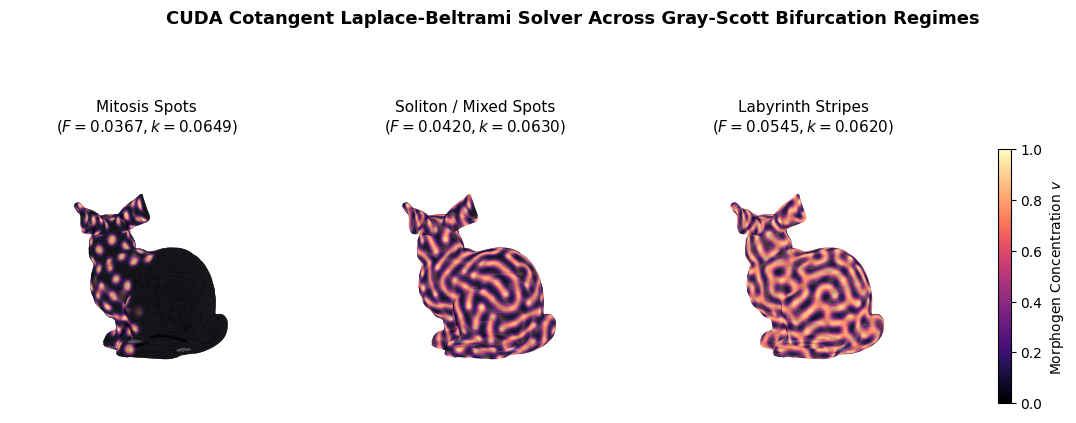

In [ ]:
import subprocess

subprocess.run(["nvcc", "-O3", "-Wno-deprecated-gpu-targets", "surface_rd_solver.cu", "-o", "surface_rd_solver"], check=True)

regimes = [
    ("0.0367", "0.0649", "sol_mitosis.bin", "Mitosis Spots\n($F=0.0367, k=0.0649$)"),
    ("0.0420", "0.0630", "sol_spots.bin",   "Soliton / Mixed Spots\n($F=0.0420, k=0.0630$)"),
    ("0.0545", "0.0620", "sol_coral.bin",   "Labyrinth Stripes\n($F=0.0545, k=0.0620$)")
]

fig = plt.figure(figsize=(15, 5.5))

for idx, (F_str, k_str, fname, title) in enumerate(regimes):
    res = subprocess.run(["./surface_rd_solver", F_str, k_str, fname], capture_output=True, text=True, check=True)
    print(res.stdout.strip())

    with open(fname, "rb") as f:
        _ = np.frombuffer(f.read(num_v * 4), dtype=np.float32)
        v_sol = np.frombuffer(f.read(num_v * 4), dtype=np.float32)

    face_v = v_sol[F_mesh].mean(axis=1)
    face_norm = (face_v - face_v.min()) / (face_v.max() - face_v.min() + 1e-8)

    ax = fig.add_subplot(1, 3, idx + 1, projection='3d')
    surf = ax.plot_trisurf(V[:, 0], V[:, 2], V[:, 1], triangles=F_mesh, cmap='magma', shade=True, linewidth=0)
    surf.set_array(face_norm)
    surf.set_clim(0.0, 1.0)
    ax.view_init(elev=15, azim=-65)
    ax.set_box_aspect([np.ptp(V[:, 0]), np.ptp(V[:, 2]), np.ptp(V[:, 1])])
    ax.axis('off')
    ax.set_title(title, fontsize=11)

plt.colorbar(surf, ax=fig.get_axes(), shrink=0.6, label="Morphogen Concentration $v$")
plt.suptitle("CUDA Cotangent Laplace-Beltrami Solver Across Gray-Scott Bifurcation Regimes", fontsize=13, fontweight='bold')
plt.show()